# Preprocessing U.S. tech job postings for salary prediction

Our goal is to predict the annualized midpoint of advertised pay ranges. Each row represents a job posting. This notebook reads the raw Freehire extract, defines the salary sample, checks target quality and duplicates, prepares skill and location fields, and exports a documented set of columns.

Run the cells in order using a Python kernel with pandas 2 or later, NumPy, `us`, and `geonamescache`. Run from the repository root or the `notebooks` directory. The notebook uses helpers adapted from the original script in `scripts/salary_preprocessing.py` and reads the checked-in skill mapping.

In [1]:
from pathlib import Path
import ast
import json
import sys

import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd()
if not (root / "scripts" / "salary_preprocessing.py").is_file():
    root = root.parent
if not (root / "scripts" / "salary_preprocessing.py").is_file():
    raise FileNotFoundError("Run from the repository root or the notebooks directory.")
sys.path.insert(0, str(root))

from scripts import salary_preprocessing as prep

archive_path = root / "data" / "freehire_tech.csv.zip"
mapping_path = root / "data" / "skill_categories.txt"
output_path = root / "data" / "cleaned_job_postings.csv"
min_rows = 50_000
min_predictors = 10

## 1. Read the raw extract and define the sample

The archive contains the raw CSV. We keep postings whose country list is exactly `['us']`, then filter to postings dated in 2026 using UTC. This describes the available extract. The date coverage below shows the actual observation window.

In [2]:
raw = prep.load_data(archive_path)
row_counts = {"Raw postings": len(raw)}
original_columns = len(raw.columns)

us_jobs = prep.filter_us_jobs(raw)
row_counts["U.S. only"] = len(us_jobs)
jobs = prep.filter_2026_jobs(us_jobs)
row_counts["U.S. only, posted in 2026"] = len(jobs)

print(f"Raw extract: {len(raw):,} rows × {original_columns} columns")
print(f"2026 posting dates (UTC): {jobs['posted_at'].min().date()} to {jobs['posted_at'].max().date()}")
display(pd.Series(row_counts, name="Rows").to_frame())
del raw, us_jobs

Raw extract: 876,684 rows × 27 columns
2026 posting dates (UTC): 2026-01-01 to 2026-08-07


,Rows
Raw postings,876684
U.S. only,364680
"U.S. only, posted in 2026",311210


## 2. Validate salary fields and construct the target

Salary prediction requires both advertised endpoints, a currency, and a pay period. We coerce pay to numeric, normalize the period and currency, and keep complete USD records. We then exclude unsupported periods, non-finite or nonpositive endpoints, and ranges whose minimum exceeds their maximum.

We annualize monthly, daily, and hourly rates using 12 months, 260 days, or 2,080 hours. The target is the midpoint of the resulting annualized bounds. These assumptions express an annualized rate. Actual yearly earnings for part-time or contract roles depend on hours worked.

In [3]:
for column in ["salary_min", "salary_max"]:
    jobs[column] = pd.to_numeric(jobs[column], errors="coerce")
for column in ["salary_period", "salary_currency"]:
    jobs[column] = jobs[column].str.strip().replace("", pd.NA)
jobs["salary_period"] = jobs["salary_period"].str.lower()

display(jobs[prep.SALARY_COLS].isna().sum().rename("Missing values").to_frame())
salary_jobs = prep.filter_salary_usd(jobs)
row_counts["Complete USD salary fields"] = len(salary_jobs)
print(f"Salary sample coverage: {len(salary_jobs) / len(jobs):.1%} of U.S.-only 2026 postings")

lower = salary_jobs["salary_min"]
upper = salary_jobs["salary_max"]
invalid_salary = pd.DataFrame({
    "Unsupported pay period": ~salary_jobs["salary_period"].isin(prep.SALARY_MULTIPLIER),
    "Non-finite endpoint": ~(np.isfinite(lower) & np.isfinite(upper)),
    "Nonpositive endpoint": (lower <= 0) | (upper <= 0),
    "Reversed endpoints": lower > upper,
})
display(invalid_salary.sum().rename("Flagged rows").to_frame())
annualized = prep.compute_salary_mid_year(salary_jobs.loc[~invalid_salary.any(axis=1)])
row_counts["Valid salary fields and ranges"] = len(annualized)
del jobs, salary_jobs

Salary sample coverage: 26.6% of U.S.-only 2026 postings


,Missing values
salary_min,223100
salary_max,223649
salary_currency,219256
salary_period,226633


,Flagged rows
Unsupported pay period,0
Non-finite endpoint,0
Nonpositive endpoint,0
Reversed endpoints,0


### Review implausible salaries

The raw extract includes values such as a $1 annual salary and a $199,158 rate tagged as hourly. For this first pass, we quarantine postings with an annualized midpoint of **$1,000 or less** or **over $1 million**, and any non-finite annualized result. These are provisional review thresholds chosen for this extract, not estimates of the market's salary limits. We keep the raw fields in the review table so excluded rows can be checked and restored if confirmed. We leave plausible high salaries in the data and avoid guessing a replacement pay period.

In [4]:
midpoint = annualized["salary_mid_year"]
extreme_salary = (
    ~np.isfinite(midpoint)
    | midpoint.le(1_000)
    | midpoint.gt(1_000_000)
)
salary_review = annualized.loc[extreme_salary, [
    "public_slug", "title", "url", "salary_min", "salary_max", "salary_period", "salary_mid_year"
]].copy()
print(f"Postings held for salary review: {len(salary_review):,}")
display(salary_review["salary_period"].value_counts().rename("Flagged rows").to_frame())
display(annualized.groupby("salary_period")["salary_mid_year"].agg(["count", "median", "min", "max"]).round(0))

clean = annualized.loc[~extreme_salary].copy()
row_counts["After salary review exclusions"] = len(clean)
display(clean.groupby("salary_period")["salary_mid_year"].agg(["count", "median", "min", "max"]).round(0))
del annualized

Postings held for salary review: 721


,Flagged rows
salary_period,
hour,556
year,86
month,79


,count,median,min,max
salary_period,,,,
day,12,156000.0,20800.0,890890.0
hour,10085,52000.0,2080.0,414248640.0
month,258,112758.0,330.0,2400000.0
year,72324,152726.0,1.0,4000000.0


,count,median,min,max
salary_period,,,,
day,12,156000.0,20800.0,890890.0
hour,9529,48880.0,2080.0,988000.0
month,179,90156.0,1140.0,960000.0
year,72238,152900.0,1372.0,925000.0


## 3. Check duplicate postings

A URL can cover more than one location or posting. We collapse records only if all raw posting fields except the unique identifier and source agree. That rule also requires the same URL, timestamp, location, and original salary. Retained rows sharing a URL get a review flag that can also be used to keep a URL together across training and validation splits.

In [5]:
comparison_cols = [
    column for column in clean.columns
    if column not in {"public_slug", "source", "salary_min_year", "salary_max_year", "salary_mid_year"}
]
duplicate = clean.duplicated(subset=comparison_cols)
clean = clean.loc[~duplicate].copy()
clean["shared_posting_url"] = clean["url"].notna() & clean["url"].duplicated(keep=False)
row_counts["After deduplication"] = len(clean)
print(f"Equivalent rows removed: {duplicate.sum():,}")
print(f"Retained rows sharing a URL: {clean['shared_posting_url'].sum():,}")

Equivalent rows removed: 424
Retained rows sharing a URL: 262


## 4. Prepare geographic fields for a later join

The script can infer a state from a city name or a phrase in free text. We record that result as `state_candidate` for review. For the future cost-of-living merge, use `state`, which accepts only a single explicit state token in the location and leaves multi-location strings unresolved. For postings identified as remote, we require that the location consist only of a remote label, an explicit state, and optionally a U.S. label. This makes the join conservative. A missing state does not remove the posting from the salary sample.

In [6]:
clean = prep.add_state_columns(clean).rename(columns={"state": "state_candidate"})
lookups = prep.build_location_lookups()
state_names = lookups["state_names"]
state_abbrs = lookups["state_abbrs"]
remote_pattern = lookups["remote_re"]
country_pattern = lookups["country_re"]

def explicit_state(location, remote):
    if not isinstance(location, str) or any(mark in location for mark in ";/|"):
        return None
    parts = prep.split_parts(location)
    candidates = {
        part if part in state_abbrs else state_names[part.lower()]
        for part in parts
        if part in state_abbrs or part.lower() in state_names
    }
    if len(candidates) != 1:
        return None
    if remote:
        qualifiers = [
            part for part in parts
            if part not in state_abbrs and part.lower() not in state_names
        ]
        if not any(remote_pattern.fullmatch(part) for part in qualifiers):
            return None
        if any(not (remote_pattern.fullmatch(part) or country_pattern.fullmatch(part))
               for part in qualifiers):
            return None
    return next(iter(candidates))

remote = (
    clean["work_mode"].eq("remote")
    | clean["location"].fillna("").map(lambda location: bool(remote_pattern.search(location)))
)
unique_inputs = pd.DataFrame({"location": clean["location"], "remote": remote}).drop_duplicates()
state_lookup = {
    (location, is_remote): explicit_state(location, is_remote)
    for location, is_remote in unique_inputs.itertuples(index=False, name=None)
    if isinstance(location, str)
}
clean["state"] = [state_lookup.get((location, is_remote)) for location, is_remote in zip(clean["location"], remote)]
clean["location_type"] = [
    "remote" if is_remote else prep.location_type(location, state, lookups)
    for location, state, is_remote in zip(clean["location"], clean["state"], remote)
]
print(f"Join-ready state coverage: {clean['state'].notna().sum():,} ({clean['state'].notna().mean():.1%})")
display(clean["location_type"].value_counts().rename("Rows").to_frame())

Join-ready state coverage: 52,515 (64.4%)


,Rows
location_type,
state,51625
remote,17428
untraditional,10799
us_only,1668
missing,14


## 5. Prepare skill and company fields

We reuse the existing nine skill categories so group IDs stay consistent with the project's checked-in mapping. Each indicator equals 1 when a posting mentions at least one skill in the group. `skills_listed` distinguishes an empty skills list from a populated list that matches no groups. The mapping is fixed for this notebook. If the team learns a new mapping for model evaluation, fit it on training data only.

Company size and industry may list multiple values. We parse the lists and preserve the distinction between null and empty. Company size is a baseline predictor for multi-hot encoding. Industry stays available for EDA and optional model experiments. Numeric experience retains its original missing values and valid zeros. Training-time imputation belongs in the model pipeline.

In [7]:
clusters = {}
for block in mapping_path.read_text(encoding="utf-8").strip().split("\n\n"):
    heading, *skills = block.splitlines()
    category_id = int(heading.split()[-1])
    if category_id in clusters or not skills:
        raise ValueError(f"Invalid skill group: {heading}")
    clusters[category_id] = skills
assert set(clusters) == set(range(prep.N_CATEGORIES))

clean = prep.add_cluster_dummies(prep.parse_skills_list(clean), clusters)
skill_cols = [f"skill_category_{i}" for i in range(prep.N_CATEGORIES)]
display(clean[skill_cols + ["skills_listed"]].agg(["sum", "mean"]).T.rename(
    columns={"sum": "Postings", "mean": "Share"}
).round(3))

for column in ["company_sizes", "company_industries"]:
    clean[column] = clean[column].map(ast.literal_eval, na_action="ignore")
    if not clean[column].dropna().map(lambda value: isinstance(value, list)).all():
        raise ValueError(f"{column} contains a non-list value.")
clean["experience_years_min"] = pd.to_numeric(clean["experience_years_min"], errors="coerce")
clean["experience_years_min"] = clean["experience_years_min"].mask(clean["experience_years_min"].lt(0))

,Postings,Share
skill_category_0,31591.0,0.387
skill_category_1,42641.0,0.523
skill_category_2,34007.0,0.417
skill_category_3,34374.0,0.422
skill_category_4,25388.0,0.311
skill_category_5,20807.0,0.255
skill_category_6,22258.0,0.273
skill_category_7,25147.0,0.308
skill_category_8,23815.0,0.292
skills_listed,68012.0,0.834


### Company size coverage

A blank cell means there is no recorded list. An empty list (`[]`) is present but contains no size band. Both count as unlisted in the variable profile. The table below shows them separately and uses all retained postings as the denominator.

In [8]:
company_sizes = clean["company_sizes"]
band_count = company_sizes.str.len()
size_status = pd.Series({
    "Blank or null": company_sizes.isna().sum(),
    "Empty list": band_count.eq(0).sum(),
    "One listed band": band_count.eq(1).sum(),
    "Multiple listed bands": band_count.gt(1).sum(),
}, name="Postings")
assert size_status.sum() == len(clean)
size_profile = size_status.to_frame()
size_profile["Share of postings"] = (size_profile["Postings"] / len(clean)).map("{:.1%}".format)
display(size_profile)

band_mentions = (
    company_sizes.explode()
    .dropna()
    .reset_index()
    .drop_duplicates()
)
band_frequency = band_mentions["company_sizes"].value_counts().rename("Postings").to_frame()
band_frequency["Share of postings"] = (band_frequency["Postings"] / len(clean)).map("{:.1%}".format)
display(band_frequency)

,Postings,Share of postings
Blank or null,1142,1.4%
Empty list,940,1.2%
One listed band,55243,67.8%
Multiple listed bands,24209,29.7%


,Postings,Share of postings
company_sizes,,
1000+,60243,73.9%
501-1000,29295,35.9%
51-200,15537,19.1%
201-500,10681,13.1%
11-50,6638,8.1%
1-10,2197,2.7%


**Model preparation.** Keep the original lists in the cleaned dataset. For modeling, multi-hot encode the six size bands because nearly 30% of postings list several. For example, a posting with `["1000+", "501-1000"]` gets a 1 in both band indicators. Each posting stays on one row. For a blank or empty list, set all band indicators to 0 and set `company_size_unlisted` to 1. Band percentages can sum to more than 100% because a posting can contribute to multiple bands.

## 6. Select and document the final columns

The dataset retains the target, baseline predictors, optional EDA fields, geographic join fields, and provenance needed to explain cleaning decisions. The baseline starts with 12 named predictors. Salary components, identifiers, and review flags are available for auditing. Use the explicit baseline list when constructing the feature matrix to keep salary components out of training.

### Missing-data decision and baseline treatment

> **Missing-data decision.** Exclude `work_mode`, `seniority`, `employment_type`, and `company_industries` from the baseline because more than 40% of their values are missing or unlisted. Keep these fields in the cleaned CSV so we can document coverage without guessing what postings did not report.
>
> **Baseline treatment.** Preserve nulls in the cleaned CSV. At modeling time, fill missing experience with the training-set median and add a missingness flag. For company size, encode every reported band and flag blank or empty lists as unlisted. The nine skill indicators and `skills_listed` are complete.

In [9]:
target = "salary_mid_year"
baseline = skill_cols + ["skills_listed", "experience_years_min", "company_sizes"]
optional = ["category", "seniority", "employment_type", "company_industries", "work_mode"]
geography = ["state", "state_candidate", "location_type", "location"]
salary_audit = ["salary_min", "salary_max", "salary_period", "salary_currency",
                "salary_min_year", "salary_max_year"]
posting_audit = ["public_slug", "url", "posted_at", "title", "company_slug",
                 "skills_list", "shared_posting_url"]
final_columns = [target] + baseline + optional + geography + salary_audit + posting_audit
final = clean.loc[:, final_columns].reset_index(drop=True)
list_cols = ["skills_list", "company_sizes", "company_industries"]
row_counts["Final cleaned dataset"] = len(final)
display(pd.Series(row_counts, name="Rows").to_frame())

,Rows
Raw postings,876684
U.S. only,364680
"U.S. only, posted in 2026",311210
Complete USD salary fields,82679
Valid salary fields and ranges,82679
After salary review exclusions,81958
After deduplication,81534
Final cleaned dataset,81534


In [10]:
definitions = {
    "salary_mid_year": "Annualized midpoint of the advertised USD salary range",
    "skills_listed": "Whether the posting lists at least one skill",
    "experience_years_min": "Minimum stated experience in years",
    "company_sizes": "One or more reported company headcount bands",
    "category": "One job-function label",
    "seniority": "Job seniority label",
    "employment_type": "Employment arrangement, such as full-time or contract",
    "company_industries": "One or more industry tags",
    "work_mode": "Reported onsite, hybrid, or remote work arrangement",
    "state": "Explicit state code for review and the future index join",
    "state_candidate": "State code inferred by the original free-text parser",
    "location_type": "Location classification, including remote or unresolved",
}
roles = {
    "Target": [target],
    "Baseline": baseline,
    "Optional EDA": optional,
    "Geography": geography[:3],
}
profile = []
for role, columns in roles.items():
    for column in columns:
        values = final[column]
        unavailable = values.isna()
        if column in list_cols:
            unavailable |= values.str.len().eq(0)
        meaning = definitions.get(column, "Posting mentions a skill from this group")
        profile.append({
            "Column": column,
            "Role": role,
            "Meaning": meaning,
            "Type": "List" if column in list_cols else str(values.dtype),
            "Missing or unlisted": int(unavailable.sum()),
            "Share": f"{unavailable.mean():.1%}",
        })
display(pd.DataFrame(profile).set_index("Column"))

,Role,Meaning,Type,Missing or unlisted,Share
Column,,,,,
salary_mid_year,Target,Annualized midpoint of the advertised USD sala...,float64,0,0.0%
skill_category_0,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_1,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_2,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_3,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_4,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_5,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_6,Baseline,Posting mentions a skill from this group,int64,0,0.0%
skill_category_7,Baseline,Posting mentions a skill from this group,int64,0,0.0%


### Predictor selection and missing-value treatment

We use 40% missing or unlisted as a practical cutoff for the first model. `work_mode` (58.6%), `seniority` (52.8%), `employment_type` (47.5%), and `company_industries` (40.8%) exceed that cutoff. Filling all those gaps with common labels would assign unreported characteristics to many postings. We exclude the four fields from the baseline and main EDA charts and retain them in the export and missingness table for transparency. This decision removes no rows. The baseline has 12 named predictors before encoding and uses all 81,534 cleaned postings for splitting.

| Field | Missing-value treatment |
|---|---|
| `skill_category_0` through `skill_category_8`, `skills_listed` | These binary fields are complete. Keep the zeros as recorded. `skills_listed` distinguishes a posting with no listed skills from one that lists skills outside the nine groups. |
| `experience_years_min` | Preserve nulls in the export and keep explicitly reported zeros. During modeling, add a missingness indicator and fill nulls with the median learned on the training split. Apply that same median to validation and test rows. |
| `company_sizes` | Multi-hot encode all reported size bands. For a blank or empty list, set all band indicators to 0 and `company_size_unlisted` to 1. |
| `category` | Use an unlisted group in descriptive summaries. If we test it as an optional predictor, one-hot encode an explicit `Unknown` level for missing values. |
| `state` and related location fields | Leave unresolved states null. When adding the cost-of-living index, use a left join to keep postings with no match, then report coverage before choosing a modeling treatment. Keep `state_candidate` for review. |
| `salary_mid_year` | The target is complete after salary screening and requires no imputation. |

Apply model-specific fills and encoding after splitting the data. Keep missing values in the cleaned export so the EDA can report observed coverage.

#### Preview of the selected fields

These five cleaned postings show the baseline predictors, job category, location fields, and salary target before model-time encoding or imputation.

In [11]:
preview_columns = baseline + ["category"] + geography + [target]
display(final.loc[:, preview_columns].head(5))

,skill_category_0,skill_category_1,skill_category_2,skill_category_3,skill_category_4,skill_category_5,skill_category_6,skill_category_7,skill_category_8,skills_listed,experience_years_min,company_sizes,category,state,state_candidate,location_type,location,salary_mid_year
0,1,1,0,1,1,1,1,0,1,1,2.0,[1000+],NaN,CA,CA,state,"Culver City, California, United States",174100.0
1,1,1,0,1,1,1,1,0,1,1,2.0,[1000+],NaN,CA,CA,state,"Novato, California, United States",174100.0
2,1,1,0,1,1,1,1,0,1,1,4.0,[1000+],NaN,CA,CA,state,"Culver City, California, United States",135030.0
3,1,1,0,1,1,1,1,0,1,1,4.0,[1000+],NaN,CA,CA,state,"Novato, California, United States",135030.0
4,0,1,0,0,0,0,0,1,0,1,2.0,[11-50],project_management,MA,MA,state,"Burlington, Massachusetts, United States",107500.0


## 7. Validate and export

The checks enforce the project's minimum of 50,000 postings and 10 predictors. The CSV stores list fields as JSON arrays. Read those cells with `json.loads` after loading the CSV, skipping nulls. Empty lists are exported as `[]`. The state-level cost-of-living index will be added after we review state matches against the index source.

In [12]:
assert len(final) >= min_rows, f"Only {len(final):,} rows after cleaning."
assert len(baseline) >= min_predictors and len(set(baseline)) == len(baseline)
assert final.columns.is_unique and final["public_slug"].is_unique
assert final[target].gt(1_000).all() and final[target].le(1_000_000).all()
assert final[skill_cols + ["skills_listed"]].isin([0, 1]).all().all()
assert not final.loc[final["skills_listed"].eq(0), skill_cols].any().any()

export = final.copy()
for column in list_cols:
    export[column] = export[column].map(json.dumps, na_action="ignore")
temporary_path = output_path.with_suffix(".csv.tmp")
export.to_csv(temporary_path, index=False)
temporary_path.replace(output_path)

reloaded = pd.read_csv(output_path)
assert reloaded.shape == final.shape and reloaded.columns.tolist() == final_columns
for column in list_cols:
    restored = reloaded[column].map(json.loads, na_action="ignore")
    assert restored.isna().equals(final[column].isna())
    present = restored.notna()
    assert restored[present].equals(final.loc[present, column])

print(f"Exported {len(final):,} postings and {len(final_columns)} columns to {output_path.relative_to(root)}.")
print(f"Baseline: {len(baseline)} named predictors before encoding.")

Exported 81,534 postings and 35 columns to data/cleaned_job_postings.csv.
Baseline: 12 named predictors before encoding.


### Preview of the cleaned dataset

The first five rows show the salary target and all baseline predictors, with job title for context. The transposed view below shows every retained field for the first three postings, including the audit and geography columns. These previews use the final dataset that is exported to CSV.

In [13]:
print(f"Cleaned dataset: {len(final):,} postings × {final.shape[1]} columns")
display(final[["title", target] + baseline].head(5))
display(final.head(3).T.rename(columns=lambda index: f"Posting {index + 1}"))

Cleaned dataset: 81,534 postings × 35 columns


,title,salary_mid_year,skill_category_0,skill_category_1,skill_category_2,skill_category_3,skill_category_4,skill_category_5,skill_category_6,skill_category_7,skill_category_8,skills_listed,experience_years_min,company_sizes
0,Lead Software Engineer - Automation,174100.0,1,1,0,1,1,1,1,0,1,1,2.0,[1000+]
1,Lead Software Engineer - Automation,174100.0,1,1,0,1,1,1,1,0,1,1,2.0,[1000+]
2,Senior Software Engineer - Automation,135030.0,1,1,0,1,1,1,1,0,1,1,4.0,[1000+]
3,Senior Software Engineer - Automation,135030.0,1,1,0,1,1,1,1,0,1,1,4.0,[1000+]
4,Operations Program Manager (Supply Chain),107500.0,0,1,0,0,0,0,0,1,0,1,2.0,[11-50]


,Posting 1,Posting 2,Posting 3
salary_mid_year,174100.0,174100.0,135030.0
skill_category_0,1,1,1
skill_category_1,1,1,1
skill_category_2,0,0,0
skill_category_3,1,1,1
skill_category_4,1,1,1
skill_category_5,1,1,1
skill_category_6,1,1,1
skill_category_7,0,0,0
skill_category_8,1,1,1


## 8. Explore salary, geography, and skill groups

These plots use the 81,534 cleaned U.S. postings with usable advertised USD salaries. The charts describe this salary-disclosing sample. The analysis uses the cleaned values before training-time imputation or encoding. To regenerate the figures, use a Python kernel with Matplotlib installed.

### Salary distribution

The histogram uses logarithmically spaced bins to show the entire retained range. The salary axis is labeled in dollars.

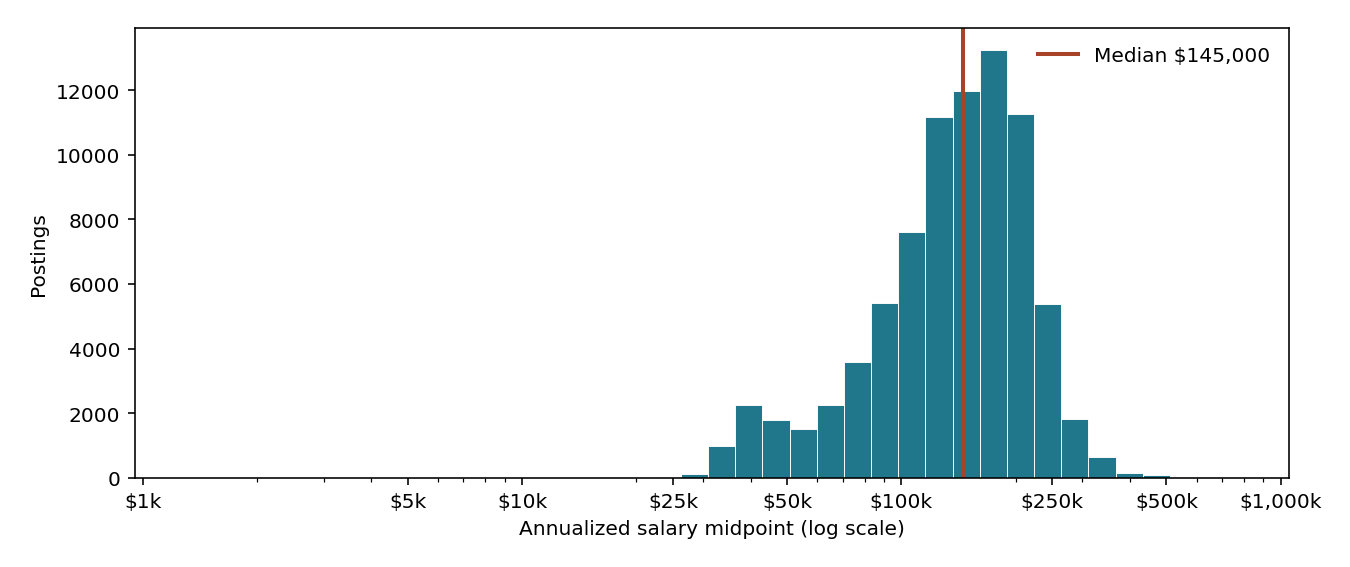

In [14]:
from io import BytesIO
from IPython.display import Image
from matplotlib import pyplot as plt
from matplotlib import colors, patches, ticker

def show_figure(figure):
    image = BytesIO()
    figure.savefig(image, format="png", dpi=145, bbox_inches="tight", pad_inches=0.2)
    plt.close(figure)
    display(Image(data=image.getvalue()))

def salary_tick(value, _position):
    return f"${value / 1_000:,.0f}k"

salary = final[target]
fig, ax = plt.subplots(figsize=(9, 3.6), layout="constrained")
bins = np.geomspace(salary.min(), salary.max(), 42)
ax.hist(salary, bins=bins, color="#20768a", edgecolor="white", linewidth=0.45)
ax.axvline(salary.median(), color="#a74428", linewidth=2, label=f"Median ${salary.median():,.0f}")
ax.set(xscale="log", xlabel="Annualized salary midpoint (log scale)", ylabel="Postings")
ax.set_xticks([1_000, 5_000, 10_000, 25_000, 50_000, 100_000, 250_000, 500_000, 1_000_000])
ax.set_xlim(950, 1_050_000)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(salary_tick))
ax.legend(frameon=False)
show_figure(fig)

**Finding.** The median is $145,000, the 90th percentile is $224,100, and the 99th percentile is about $317,209. Some values still extend well beyond the 99th percentile after salary screening. We will report validation MAE in dollars and check errors across the salary range so the upper tail stays visible.

### Average advertised salary by state

This U.S. tile map uses one tile per state and D.C. in approximate geographic positions. We use the explicit `state` field and mask areas with fewer than 30 postings. The companion table shows counts, means, and medians for every area with a known state. Salaries are in nominal dollars.

State coverage: 52,515 of 81,534 postings.


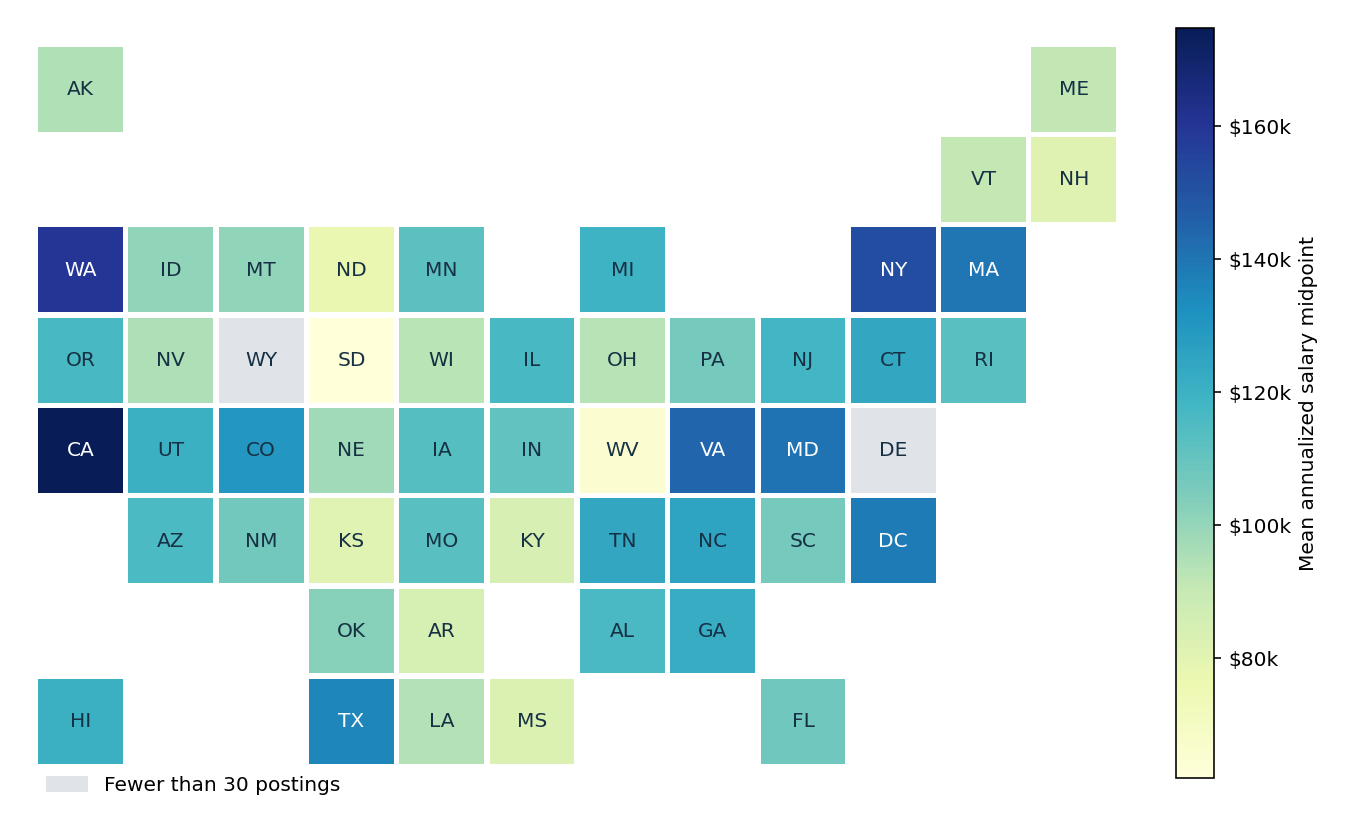

,postings,mean,median
state,,,
CA,13725,174730.0,175000.0
WA,2943,160146.0,167500.0
NY,5036,152096.0,152500.0
VA,3685,144068.0,142400.0
MD,1968,140630.0,142300.0
MA,3050,139887.0,137500.0
DC,60,138279.0,130750.0
TX,2674,135319.0,130000.0
CO,1835,130007.0,129375.0


In [15]:
state_salary = final.groupby("state")[target].agg(postings="size", mean="mean", median="median")
min_state_postings = 30
print(f"State coverage: {state_salary['postings'].sum():,} of {len(final):,} postings.")
state_grid = [
    "AK -- -- -- -- -- -- -- -- -- -- ME",
    "-- -- -- -- -- -- -- -- -- -- VT NH",
    "WA ID MT ND MN -- MI -- -- NY MA --",
    "OR NV WY SD WI IL OH PA NJ CT RI --",
    "CA UT CO NE IA IN WV VA MD DE -- --",
    "-- AZ NM KS MO KY TN NC SC DC -- --",
    "-- -- -- OK AR -- AL GA -- -- -- --",
    "HI -- -- TX LA MS -- -- FL -- -- --",
]
tiles = [(row, col, code) for row, line in enumerate(state_grid)
         for col, code in enumerate(line.split()) if code != "--"]
tile_codes = [code for _, _, code in tiles]
assert len(tile_codes) == len(set(tile_codes)) == 51
assert set(tile_codes) == prep.build_location_lookups()["state_abbrs"]
eligible = state_salary.loc[state_salary["postings"].ge(min_state_postings), "mean"]
norm = colors.Normalize(vmin=eligible.min(), vmax=eligible.max())
palette = plt.get_cmap("YlGnBu")
fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
for row, col, code in tiles:
    value = eligible.get(code)
    fill = "#e0e4e8" if value is None else palette(norm(value))
    ax.add_patch(patches.Rectangle((col, row), 0.94, 0.94, facecolor=fill))
    ax.text(col + 0.47, row + 0.47, code, ha="center", va="center",
            color="white" if value is not None and norm(value) > 0.62 else "#163044")
ax.set(xlim=(-0.1, 12), ylim=(8, -0.1), aspect="equal")
ax.axis("off")
ax.legend(handles=[patches.Patch(color="#e0e4e8", label=f"Fewer than {min_state_postings} postings")],
          loc="lower left", bbox_to_anchor=(0, -0.06), frameon=False)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=palette), ax=ax, fraction=0.045,
             format=ticker.FuncFormatter(salary_tick), label="Mean annualized salary midpoint")
show_figure(fig)
display(state_salary.sort_values("mean", ascending=False).round({"mean": 0, "median": 0}))

**Finding.** An explicit state is available for 64.4% of postings. California averages about $175,000 across 13,725 postings, while Washington averages about $160,000 across 2,943. Delaware and Wyoming have fewer than 30 postings each and are shaded gray. The map reflects the mix of jobs within each state, which matters when evaluating the geographic feature and cost-of-living join.

### Skill groups and advertised salary

Among postings with at least one listed skill, compare median salary when each skill group is mentioned and when it is absent. The table also reports sample sizes and point-biserial correlation, calculated as Pearson correlation between the binary group indicator and annualized salary.

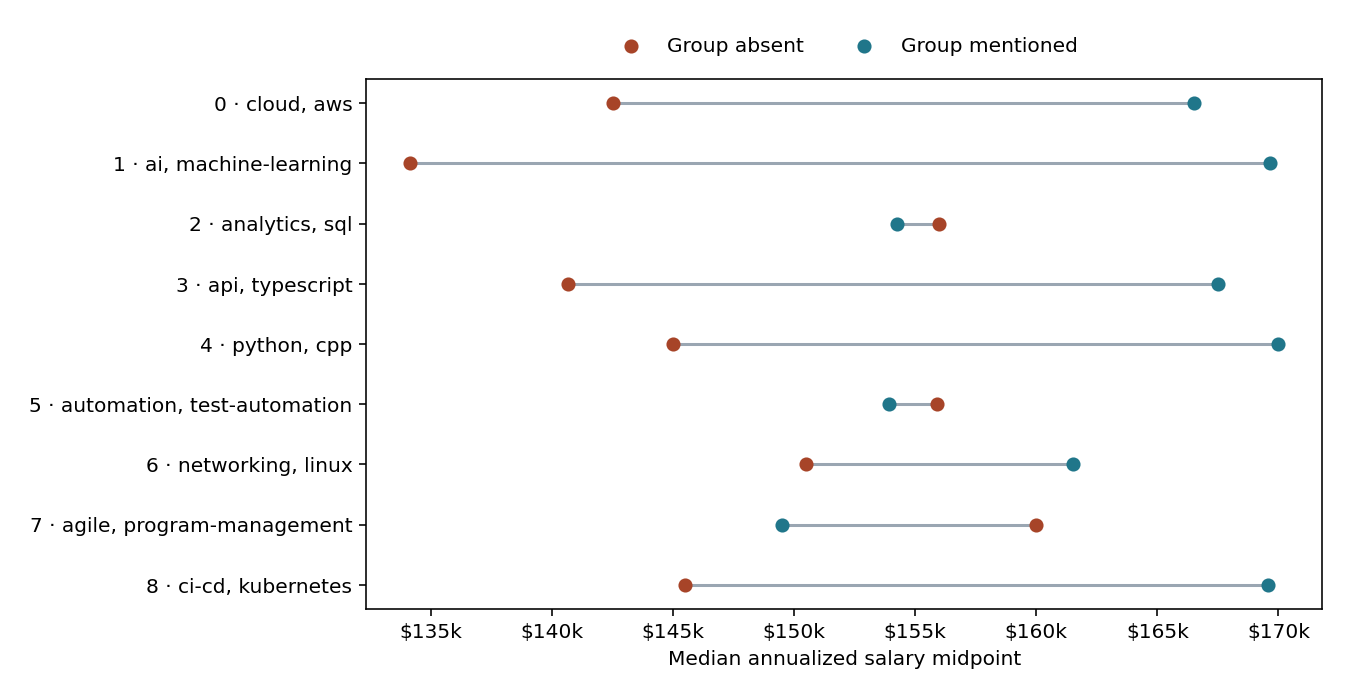

,Absent postings,Present postings,Absent median,Present median,Correlation
Skill group and examples,,,,,
"0 · cloud, aws",36421,31591,142500.0,166500.0,0.171
"1 · ai, machine-learning",25371,42641,134125.0,169650.0,0.270
"2 · analytics, sql",34005,34007,156000.0,154250.0,-0.009
"3 · api, typescript",33638,34374,140650.0,167500.0,0.180
"4 · python, cpp",42624,25388,145000.0,170000.0,0.200
"5 · automation, test-automation",47205,20807,155900.0,153900.0,-0.007
"6 · networking, linux",45754,22258,150504.0,161500.0,0.085
"7 · agile, program-management",42865,25147,160000.0,149500.0,-0.079
"8 · ci-cd, kubernetes",44197,23815,145500.0,169560.0,0.168


In [16]:
with_skills = final.loc[final["skills_listed"].eq(1)]
skill_labels = [f"{i} · {', '.join(clusters[i][:2])}" for i in range(len(skill_cols))]
skill_salary = []
for column, label in zip(skill_cols, skill_labels):
    absent = with_skills.loc[with_skills[column].eq(0), target]
    present = with_skills.loc[with_skills[column].eq(1), target]
    skill_salary.append({
        "Skill group and examples": label,
        "Absent postings": len(absent), "Present postings": len(present),
        "Absent median": absent.median(), "Present median": present.median(),
        "Correlation": with_skills[column].corr(with_skills[target]),
    })
skill_salary = pd.DataFrame(skill_salary).set_index("Skill group and examples")
positions = np.arange(len(skill_salary))
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
ax.hlines(positions, skill_salary["Absent median"], skill_salary["Present median"], color="#9aa6b2")
ax.scatter(skill_salary["Absent median"], positions, color="#a74428", label="Group absent", zorder=3)
ax.scatter(skill_salary["Present median"], positions, color="#20768a", label="Group mentioned", zorder=3)
ax.set_yticks(positions, skill_salary.index)
ax.invert_yaxis()
ax.set_xlabel("Median annualized salary midpoint")
ax.xaxis.set_major_formatter(ticker.FuncFormatter(salary_tick))
ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2)
show_figure(fig)
display(skill_salary.round({"Absent median": 0, "Present median": 0, "Correlation": 3}))

**Finding.** Group 1 (examples include AI and machine learning) has the strongest positive correlation among the nine groups in this comparison, at about 0.27. Its median is $169,650 when mentioned and $134,125 when absent. These are unadjusted associations. Job function, experience, company size, and geography can all contribute to the difference.

### Job category × skill group

Each cell is the share of **all** postings in that row that mention at least one skill in the group. The eight most common named categories are shown alongside a separate unlisted-category row. Counts accompany the row labels. A posting can mention multiple groups.

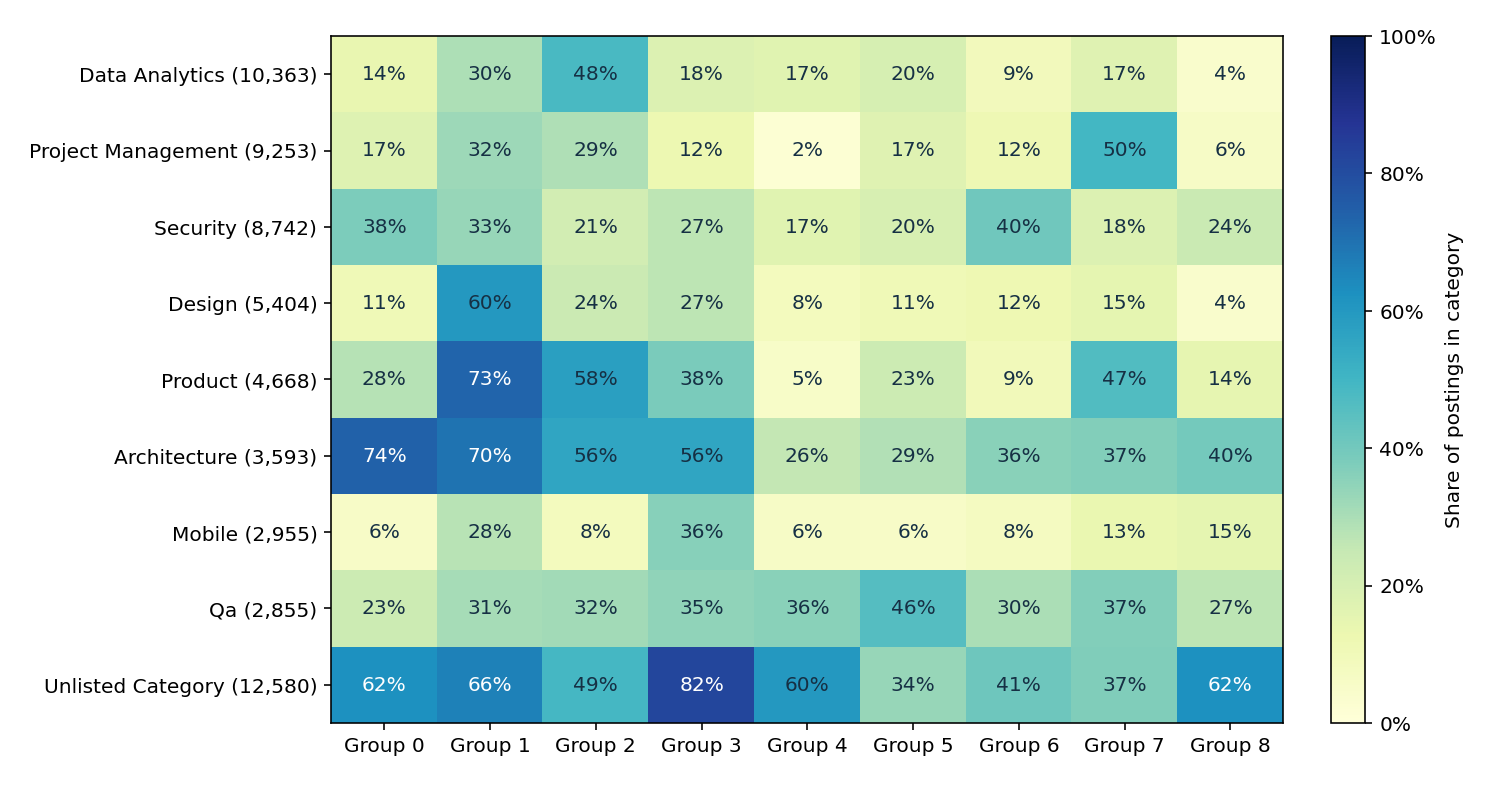

In [17]:
top_categories = final["category"].value_counts().head(8).index
category_rows = pd.concat([
    final.loc[final["category"].isin(top_categories), ["category"] + skill_cols],
    final.loc[final["category"].isna(), ["category"] + skill_cols].assign(category="Unlisted category"),
])
category_groups = category_rows.groupby("category")
row_order = [*top_categories, "Unlisted category"]
shares = category_groups[skill_cols].mean().reindex(row_order)
counts = category_groups.size().reindex(row_order)
row_labels = [
    f"{name.replace('_', ' ').title()} ({counts.loc[name]:,})" for name in shares.index
]
fig, ax = plt.subplots(figsize=(10, 5.1), layout="constrained")
image = ax.imshow(shares, cmap="YlGnBu", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(skill_cols)), [f"Group {i}" for i in range(len(skill_cols))])
ax.set_yticks(range(len(row_labels)), row_labels)
for (row, col), share in np.ndenumerate(shares.to_numpy()):
    ax.text(col, row, f"{share:.0%}", ha="center", va="center",
            color="white" if share >= 0.62 else "#163044")
fig.colorbar(image, ax=ax, format=ticker.PercentFormatter(1), label="Share of postings in category")
show_figure(fig)

**Finding.** Group 1 appears in about 60% of design postings and 73% of product postings. Group 2 shows a larger difference, at about 24% for design and 58% for product. The overlap and differences motivate testing whether job category improves validation MAE beyond the nine skill indicators.